In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import shutil
from scipy.signal import savgol_filter
import pandas as pd
from pathlib import Path
import re
import pyarrow.feather as feather
import sys
import joblib
from scipy.signal import find_peaks

from random import randint

### Set global variables

In [3]:
SAVEFILES = True
OVERWRITE = True

SAVE_DIR = Path("~/ECM_mod_output/").expanduser()
LYAP_DIR = Path(SAVE_DIR,'sweep_UMAP')
# LYAP_DIR.mkdir(parents=True, exist_ok=True)
EMBED_DIR = Path('../../Data','UMAP_embedding_ode') # location of saved embedding files for each condition
SET_JPARAM = False

USE_ORIGINAL = False # set to true to automatically download the original data from Dropbox

rcParams.update({'figure.autolayout': True})

sys_type = sys.platform
if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

### Load UMAP embedding of Lyapunov data
UMAP embeddings should be `LYAP_DIR`. If they are not detected, they will be downloaded automatically.  

NOTE: Compressed LYAP_DIR data is ~50 MB. 

In [4]:
LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding' in f]
# if len(LYAP_filepaths) < 2000 or USE_ORIGINAL:
#     print(f'Could not find Lyapnunov data; downloading to {LYAP_DIR}')
#     !wget -O LYAP.zip 'https://www.dropbox.com/scl/fi/fxvzth5roj9fwvakjnlzl/Lyap_analysis.zip?rlkey=neodaaajtyk4lt1boq6bhoxnr&dl=1'
#     !unzip LYAP.zip
#     shutil.rmtree(LYAP_DIR)
#     shutil.move('./Lyap_analysis/', SAVE_DIR)
#     os.remove('./LYAP.zip')
#     LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding_' in f]

LYAP_filepaths.sort()

In [5]:
len(LYAP_filepaths)

453

In [6]:
LYAP_filepaths[:5]

['C:\\Users\\olesk\\ECM_mod_output\\sweep_UMAP\\embedding_DMSO_range_000.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\sweep_UMAP\\embedding_DMSO_range_001.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\sweep_UMAP\\embedding_DMSO_range_002.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\sweep_UMAP\\embedding_DMSO_range_003.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\sweep_UMAP\\embedding_DMSO_range_004.csv']

In [7]:
filenames_erl = [f for f in LYAP_filepaths if 'ERL' in f]
filenames_erl.sort()

if Path(SAVE_DIR,'sweep_IMT_output/ERL_IMT.csv').exists():
    ode_divs_erl = np.genfromtxt(str(Path(SAVE_DIR,'sweep_IMT_output/ERL_IMT.csv')), delimiter=',')
else:
    ode_divs_erl = np.genfromtxt(Path('../../Data/Lyapunov_data/erl_IMT.csv'), delimiter=',')

# if Path(SAVE_DIR,'lyap_erl.csv').exists():
#     lyap_erl = np.genfromtxt(Path(SAVE_DIR,'lyap_erl.csv'), delimiter=',')
# else:
#     lyap_erl = np.genfromtxt(Path('../../Data/Lyapunov_data/lyap_erl.csv'), delimiter=',')

In [8]:
len(ode_divs_erl)

151

In [9]:
len(filenames_erl)

151

In [10]:
filenames_dmso = [f for f in LYAP_filepaths if 'DMSO' in f]
filenames_dmso.sort()

if Path(SAVE_DIR,'sweep_IMT_output/DMSO_IMT.csv').exists():
    ode_divs_dmso = np.genfromtxt(str(Path(SAVE_DIR,'sweep_IMT_output/DMSO_IMT.csv')), delimiter=',')
else:
    ode_divs_dmso = np.genfromtxt(Path('../../Data/Lyapunov_data/dmso_IMT.csv'), delimiter=',')

# if Path(SAVE_DIR,'lyap_dmso.csv').exists():
#     lyap_dmso = np.genfromtxt(Path(SAVE_DIR,'lyap_dmso.csv'), delimiter=',')
# else:
#     lyap_dmso = np.genfromtxt(Path('../../Data/Lyapunov_data/lyap_dmso.csv'), delimiter=',')

In [12]:
filenames_low = [f for f in LYAP_filepaths if 'LOW' in f]
filenames_low.sort()

if Path(SAVE_DIR,'sweep_IMT_output/LOW_IMT.csv').exists():
    ode_divs_low = np.genfromtxt(str(Path(SAVE_DIR,'sweep_IMT_output/LOW_IMT.csv')), delimiter=',')
else:
    ode_divs_low = np.genfromtxt(Path('../../Data/Lyapunov_data/dmso_IMT.csv'), delimiter=',')

# if Path(SAVE_DIR,'lyap_dmso.csv').exists():
#     lyap_dmso = np.genfromtxt(Path(SAVE_DIR,'lyap_dmso.csv'), delimiter=',')
# else:
#     lyap_dmso = np.genfromtxt(Path('../../Data/Lyapunov_data/lyap_dmso.csv'), delimiter=',')

In [13]:
len(filenames_low)

151

In [14]:
# ------------------------------------------------------------------
# Load updated Lyapunov summary CSV
# ------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()  # or Path(__file__).parent if in a script

PROJECT_ROOT = NOTEBOOK_DIR.parent.parent
LYAP_SUMMARY_CSV = PROJECT_ROOT / "Python" / "LYAP_FIGURES" / "_summaries" / "lyap_means_with_markers.csv"
lyap_df = pd.read_csv(LYAP_SUMMARY_CSV)

# enforce expected treatment order
treatments = ["DMSO", "ERL", "LOW"]

# sort in sweep order
lyap_df = lyap_df.sort_values(["treatment", "index"]).reset_index(drop=True)


summary_by_treatment = {}
for treatment in treatments:
    sub = lyap_df.loc[lyap_df["treatment"] == treatment].sort_values("index").reset_index(drop=True)

    if len(sub) != 151:
        raise ValueError(f"{treatment} has {len(sub)} rows, expected 151")

    summary_by_treatment[treatment] = {
        "mean_lyap": sub["mean_lyap"].to_numpy(dtype=float),
        "dyn_state": sub["dyn_state"].to_numpy(dtype=object),
        "steady_lambda_real": sub["steady_lambda_real"].to_numpy(dtype=float),
        "AKT": sub["AKT"].to_numpy(dtype=float),
        "FAK": sub["FAK"].to_numpy(dtype=float),
        "ERK": sub["ERK"].to_numpy(dtype=float),
        "index": sub["index"].to_numpy(dtype=int),
    }

lyap_dmso = summary_by_treatment["DMSO"]["mean_lyap"]
lyap_erl  = summary_by_treatment["ERL"]["mean_lyap"]
lyap_low  = summary_by_treatment["LOW"]["mean_lyap"]

state_dmso = summary_by_treatment["DMSO"]["dyn_state"]
state_erl  = summary_by_treatment["ERL"]["dyn_state"]
state_low  = summary_by_treatment["LOW"]["dyn_state"]

steady_dmso = summary_by_treatment["DMSO"]["steady_lambda_real"]
steady_erl  = summary_by_treatment["ERL"]["steady_lambda_real"]
steady_low  = summary_by_treatment["LOW"]["steady_lambda_real"]

In [15]:
def _interp_nans(y):
    y = np.asarray(y, dtype=float)
    x = np.arange(y.size)
    good = np.isfinite(y)
    if good.sum() == 0:
        return y.copy()
    if good.sum() == 1:
        out = np.full_like(y, np.nan)
        out[:] = y[good][0]
        return out
    return np.interp(x, x[good], y[good])

def smooth_series(y, window=11):
    y_filled = _interp_nans(y)
    w = int(window)
    if w < 3:
        return y_filled
    if w % 2 == 0:
        w += 1
    pad = w // 2
    y_pad = np.pad(y_filled, (pad, pad), mode="edge")
    kernel = np.ones(w, dtype=float) / w
    return np.convolve(y_pad, kernel, mode="valid")

def make_line_without_steady(y_raw, states, y_steady, window=11):
    y_smooth = smooth_series(y_raw, window=window)
    steady_mask = (states == "steady_state") & np.isfinite(y_steady)
    y_line = y_smooth.copy()
    y_line[steady_mask] = np.nan
    return y_line, y_smooth, steady_mask

In [12]:
# #Load low signal embeddings
# names = [
#     'embedding_off_low_end',
#     'embedding_off_00_end',
#     'embedding_off_05_end',
#     'embedding_off_10_end',
#     'embedding_off_15_end',
#     'embedding_off_20_end',
#     'embedding_off_25_end',
#     'embedding_off_30_end',
#     'embedding_on_60_end',
# ]
# embeddings = {}
# for n in names:
#     embeddings[n] = joblib.load(SAVE_DIR / f'{n}.sav')

In [16]:
assert len(filenames_dmso) == len(filenames_erl) == 151

In [17]:
all_divs = np.concatenate((ode_divs_erl, ode_divs_dmso, ode_divs_low))
ode_max = max(all_divs)
ode_min = min(all_divs)


In [15]:
# SAVE_DIR = Path(Path.home(),'ECM_mod_output/UMAP/low_ODE_embeddings')
#
# if not SAVE_DIR.exists():
#     SAVE_DIR.mkdir()

In [16]:
# LYAP_filepaths = [str(Path(SAVE_DIR, f)) for f in os.listdir(SAVE_DIR) if '.csv' in f]

In [17]:
# low_embed_01 = [f for f in LYAP_filepaths if 'low_ERK01' in f]
# low_embed_01.sort()
# low_embed_02 = [f for f in LYAP_filepaths if 'low_ERK02' in f]
# low_embed_02.sort()
# low_embed_1 = [f for f in LYAP_filepaths if 'low_ERK1' in f]
# low_embed_1.sort()

In [18]:
# len(low_embed_02)

51

In [19]:
# hi_embed_01 = [f for f in LYAP_filepaths if 'hi_ERK01' in f]
# hi_embed_01.sort()
# mid_embed_01 = [f for f in LYAP_filepaths if 'mid_ERK01' in f]
# mid_embed_01.sort()

In [20]:
# filenames_dmso = filenames_dmso[::10]
# filenames_erl = filenames_erl[::10]

In [21]:
# filenames_dmso = low_embed_1 + filenames_dmso
# filenames_erl = low_embed_02 + filenames_erl

In [18]:
# low_embed = low_embed_01[:-1] + mid_embed_01[:-1] + hi_embed_01

low_embed = filenames_low

In [19]:
size = (12,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

In [20]:
filenames_dmso[0]

'C:\\Users\\olesk\\ECM_mod_output\\sweep_UMAP\\embedding_DMSO_range_000.csv'

C:\Users\olesk\AppData\Local\Temp\ipykernel_11908\3630247622.py:194: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a)
C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


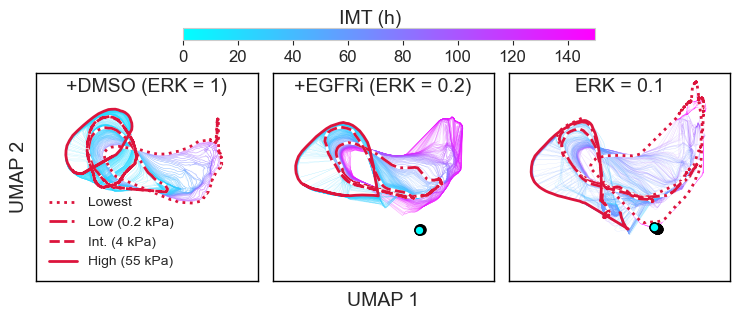

In [30]:
# ---------------------------------------------------------
# IMT-colored UMAP trajectories
# styled like the updated 3-panel Fig. 4 layout
# ---------------------------------------------------------
size = (7.5, 3)

params = {
    "axes.titley": 1,
    "axes.titlepad": -14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
}
plt.rcParams.update(params)

# IMT color scale
imt_all  = np.concatenate([ode_divs_dmso, ode_divs_erl, ode_divs_low])
norm_imt = plt.Normalize(np.nanmin(imt_all), 150)
cm_imt   = plt.cm.cool
sm_imt   = plt.cm.ScalarMappable(cmap=cm_imt, norm=norm_imt)
sm_imt.set_array([])

xmin, xmax = -9, 18
ymin, ymax = -9, 15

fig, axes = plt.subplots(
    1, 3,
    figsize=size,
    gridspec_kw={"width_ratios": [1, 1, 1]},
)

fig.suptitle("IMT (h)", fontsize=14, y=1.05)

for ax in axes:
    ax.set_facecolor("white")
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.0)

# ── Non-steady-state (oscillating) indices per treatment ─────────────────────
dmso_osc_idx = lyap_df[
    (lyap_df.treatment == "DMSO") & (lyap_df.dyn_state != "steady_state")
]["index"].values

erl_osc_idx = lyap_df[
    (lyap_df.treatment == "ERL") & (lyap_df.dyn_state != "steady_state")
]["index"].values

low_osc_idx = lyap_df[
    (lyap_df.treatment == "LOW") & (lyap_df.dyn_state != "steady_state")
]["index"].values

plot_map = [
    ("DMSO", filenames_dmso, ode_divs_dmso, axes[0], "+DMSO (ERK = 1)", dmso_osc_idx),
    ("ERL",  filenames_erl,  ode_divs_erl,  axes[1], "+EGFRi (ERK = 0.2)",  erl_osc_idx),
    ("LOW",  low_embed,      ode_divs_low,  axes[2], "ERK = 0.1",   low_osc_idx),
]

for treatment, file_list, imt_vals, ax, title, osc_idx in plot_map:
    if len(file_list) != len(imt_vals):
        raise ValueError(
            f"{treatment}: number of embedding files ({len(file_list)}) "
            f"does not match number of IMT values ({len(imt_vals)})"
        )

    # Only plot oscillating (non-steady-state) trajectories
    for i in osc_idx:
        tmp_emb = np.genfromtxt(file_list[i], delimiter=",")

        if tmp_emb.shape[0] > 3000:
            half_len = tmp_emb.shape[0] // 2
            tmp_emb  = tmp_emb[:half_len]

        ax.plot(
            tmp_emb[:, 0],
            tmp_emb[:, 1],
            color=cm_imt(norm_imt(imt_vals[i])),
            lw=0.1,
            alpha=0.5,
        )

    ax.set_xlim([xmin, xmax])
    ax.set_ylim([ymin, ymax])
    ax.title.set_text(title)
    # ax.set_xticks([xmin, 0, 10, 20] if xmin <= 0 else [xmin, xmax])
    # ax.set_yticks([0, 5, 10, 15])
    ax.set_xticks([])
    ax.set_yticks([])

# ── Tick labels ───────────────────────────────────────────────────────────────
for ax in axes:
    ax.set_xticklabels([])
    ax.set_yticklabels([])

# ── Highlighted example trajectories ─────────────────────────────────────────
lw = 2

# DMSO examples
tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dotted",  label="Lowest")

tmp_emb = np.genfromtxt(filenames_dmso[51], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashdot", label="Low (0.2 kPa)")

tmp_emb = np.genfromtxt(filenames_dmso[101], delimiter=",")
tmp_l   = int(len(tmp_emb) / 2)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashed",  label="Int. (4 kPa)")

tmp_emb = np.genfromtxt(filenames_dmso[150], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, label="High (55 kPa)")

# ERL examples
tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[-20:, 0], tmp_emb[-20:, 1], color="white",   lw=lw)
axes[1].plot(tmp_emb[-20:, 0], tmp_emb[-20:, 1], color="crimson", lw=lw, linestyle="dotted",  label="Low")

tmp_emb = np.genfromtxt(filenames_erl[51], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashdot", label="Soft")

tmp_emb = np.genfromtxt(filenames_erl[101], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashed",  label="Int.")

tmp_emb = np.genfromtxt(filenames_erl[150], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, label="Stiff")

# LOW examples
tmp_emb = np.genfromtxt(low_embed[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dotted",  label="Low")

tmp_emb = np.genfromtxt(low_embed[51], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashdot", label="Soft")

tmp_emb = np.genfromtxt(low_embed[101], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashed",  label="Int.")

tmp_emb = np.genfromtxt(low_embed[150], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, label="Stiff")

# ── Steady-state point attractors ────────────────────────────────────────────
erl_idx = lyap_df[
    (lyap_df.treatment == "ERL") & (lyap_df.dyn_state == "steady_state")
]["index"].values

low_idx = lyap_df[
    (lyap_df.treatment == "LOW") & (lyap_df.dyn_state == "steady_state")
]["index"].values

coords_erl = np.array([np.genfromtxt(filenames_erl[i], delimiter=",")[-1] for i in erl_idx])
coords_low = np.array([np.genfromtxt(low_embed[i],     delimiter=",")[-1] for i in low_idx])

axes[1].scatter(coords_erl[:, 0], coords_erl[:, 1], s=40,
                facecolor=cm_imt(norm_imt(0)), edgecolor="black", zorder=6)
axes[2].scatter(coords_low[:, 0], coords_low[:, 1], s=40,
                facecolor=cm_imt(norm_imt(0)), edgecolor="black", zorder=6)

# ── Legend, layout, colorbar ─────────────────────────────────────────────────
axes[0].legend(loc=3, facecolor='white', frameon=False, fontsize=10)

fig.subplots_adjust(top=0.82, wspace=0.05)

cbar_ax = fig.add_axes([0.25, 0.95, 0.55, 0.04])
fig.colorbar(sm_imt, cax=cbar_ax, orientation="horizontal")

ax_shared = fig.add_subplot(111, frameon=False)
ax_shared.set_xticks([])
ax_shared.set_yticks([])
ax_shared.set_xlabel("UMAP 1", labelpad=8)
ax_shared.set_ylabel("UMAP 2", labelpad=6)

fig4a = Path(SAVE_DIR, 'fig4a.svg')

if SAVEFILES and (OVERWRITE or not fig4a.exists()):
    plt.savefig(fig4a)
else:
    plt.figure()

plt.show()

In [31]:
erl_idx

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64)

In [32]:
tmp_emb = np.genfromtxt(low_embed[0], delimiter=",")
print(len(tmp_emb))

3993


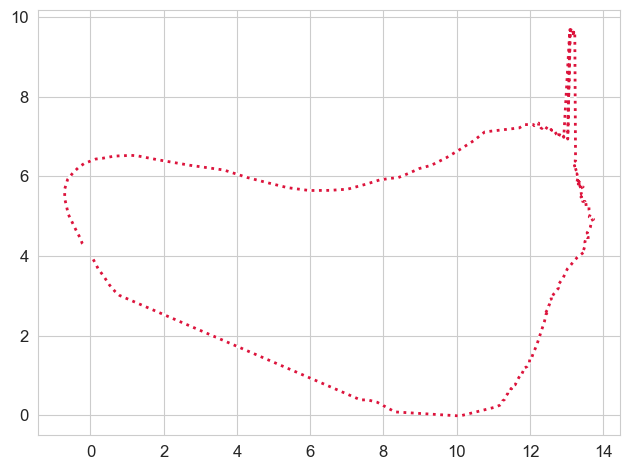

In [33]:
tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
plt.plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
plt.plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dotted", )

# tmp_emb = np.genfromtxt(low_embed[-1], delimiter=",")
# plt.plot(tmp_emb[:, 0], tmp_emb[:, 1])
#
# tmp_emb = np.genfromtxt(filenames_erl[9], delimiter=",")
# print(len(tmp_emb))
# half_len = tmp_emb.shape[0] // 2
# plt.plot(tmp_emb[half_len:, 0], tmp_emb[half_len:, 1])
#
# tmp_emb = np.genfromtxt(low_embed[42], delimiter=",")
# print(len(tmp_emb))
# half_len = tmp_emb.shape[0] // 2
# plt.plot(tmp_emb[half_len:, 0], tmp_emb[half_len:, 1])

# tmp_emb = np.genfromtxt(low_embed[8], delimiter=",")
# plt.plot(tmp_emb[:, 0], tmp_emb[:, 1])


# tmp_emb = np.genfromtxt(low_embed[-1], delimiter=",")
# plt.plot(tmp_emb[:, 0], tmp_emb[:, 1])

# tmp_emb = np.genfromtxt(filenames_erl[3], delimiter=",")
# plt.plot(tmp_emb[:, 0], tmp_emb[:, 1])

Text(0, 0.5, 'IMT (h)')

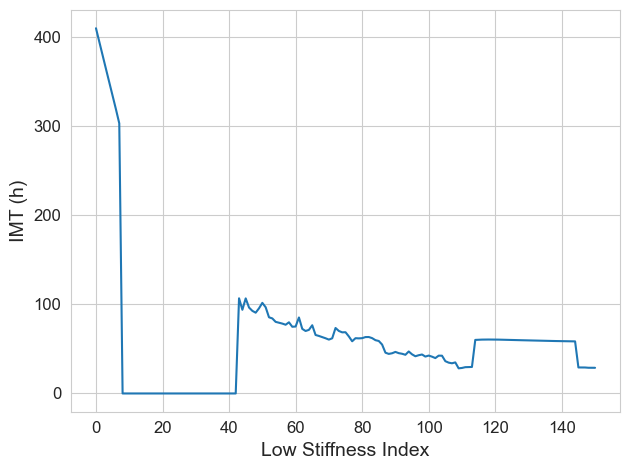

In [34]:
plt.plot(ode_divs_low)
plt.xlabel("Low Stiffness Index")
plt.ylabel("IMT (h)")

C:\Users\olesk\AppData\Local\Temp\ipykernel_11908\3504890385.py:190: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4b)
C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


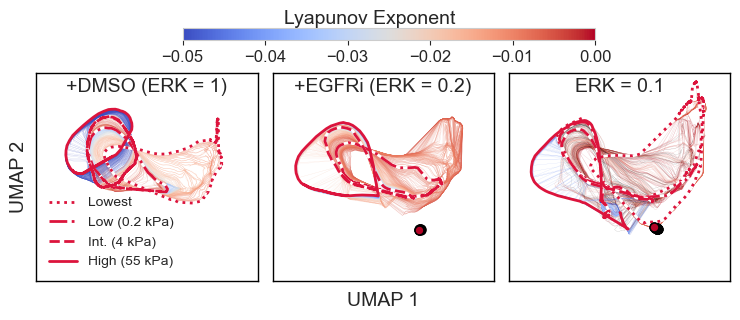

In [35]:
# ---------------------------------------------------------
# Lyapunov-colored UMAP trajectories using updated summary
# styled like the older Fig. 4 panel layout
# ---------------------------------------------------------
size = (7.5, 3)

params = {
    "axes.titley": 1,
    "axes.titlepad": -14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
}
plt.rcParams.update(params)

# Lyapunov color scale
norm_lyap = plt.Normalize(-0.05, 0.0)
cm_lyap   = plt.cm.coolwarm
sm_lyap   = plt.cm.ScalarMappable(cmap=cm_lyap, norm=norm_lyap)
sm_lyap.set_array([])

xmin, xmax = -9, 18
ymin, ymax = -9, 15

fig, axes = plt.subplots(
    1, 3,
    figsize=size,
    gridspec_kw={"width_ratios": [1, 1, 1]},
)

fig.suptitle("Lyapunov Exponent", fontsize=14, y=1.05)

for ax in axes:
    ax.set_facecolor("white")
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.0)

# ── Non-steady-state (oscillating) indices per treatment ─────────────────────
dmso_osc_idx = lyap_df[
    (lyap_df.treatment == "DMSO") & (lyap_df.dyn_state != "steady_state")
]["index"].values

erl_osc_idx = lyap_df[
    (lyap_df.treatment == "ERL") & (lyap_df.dyn_state != "steady_state")
]["index"].values

low_osc_idx = lyap_df[
    (lyap_df.treatment == "LOW") & (lyap_df.dyn_state != "steady_state")
]["index"].values

plot_map = [
    ("DMSO", filenames_dmso, axes[0], "+DMSO (ERK = 1)", dmso_osc_idx),
    ("ERL",  filenames_erl,  axes[1], "+EGFRi (ERK = 0.2)",  erl_osc_idx),
    ("LOW",  low_embed,      axes[2], "ERK = 0.1",   low_osc_idx),
]

for treatment, file_list, ax, title, osc_idx in plot_map:
    vals = summary_by_treatment[treatment]["mean_lyap"]

    if len(file_list) != len(vals):
        raise ValueError(
            f"{treatment}: number of embedding files ({len(file_list)}) "
            f"does not match summary rows ({len(vals)})"
        )

    # Only plot oscillating (non-steady-state) trajectories
    for i in osc_idx:
        tmp_emb = np.genfromtxt(file_list[i], delimiter=",")

        ax.plot(
            tmp_emb[:, 0],
            tmp_emb[:, 1],
            color=cm_lyap(norm_lyap(vals[i])),
            lw=0.1,
            alpha=0.5,
        )

    ax.set_xlim([xmin, xmax])
    ax.set_ylim([ymin, ymax])
    ax.title.set_text(title)
    # ax.set_xticks([xmin, 0, 10, 20] if xmin <= 0 else [xmin, xmax])
    # ax.set_yticks([0, 5, 10, 15])
    ax.set_xticks([])
    ax.set_yticks([])

# ── Highlighted example trajectories ─────────────────────────────────────────
lw = 2

# DMSO examples
tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dotted",  label="Lowest")

tmp_emb = np.genfromtxt(filenames_dmso[51], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashdot", label="Low (0.2 kPa)")

tmp_emb = np.genfromtxt(filenames_dmso[101], delimiter=",")
tmp_l   = int(len(tmp_emb) / 2)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashed",  label="Int. (4 kPa)")

tmp_emb = np.genfromtxt(filenames_dmso[150], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, label="High (55 kPa)")

# ERL examples
tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[-20:, 0], tmp_emb[-20:, 1], color="white",   lw=lw)
axes[1].plot(tmp_emb[-20:, 0], tmp_emb[-20:, 1], color="crimson", lw=lw, linestyle="dotted",  label="Low")

tmp_emb = np.genfromtxt(filenames_erl[51], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashdot", label="Soft")

tmp_emb = np.genfromtxt(filenames_erl[101], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashed",  label="Int.")

tmp_emb = np.genfromtxt(filenames_erl[150], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, label="Stiff")

# LOW examples
tmp_emb = np.genfromtxt(low_embed[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dotted",  label="Low")

tmp_emb = np.genfromtxt(low_embed[51], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashdot", label="Soft")

tmp_emb = np.genfromtxt(low_embed[101], delimiter=",")
tmp_l   = int(len(tmp_emb) / 5)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="white",   lw=lw)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, linestyle="dashed",  label="Int.")

tmp_emb = np.genfromtxt(low_embed[150], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
axes[2].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color="crimson", lw=lw, label="Stiff")

# ── Steady-state point attractors ────────────────────────────────────────────
erl_idx = lyap_df[
    (lyap_df.treatment == "ERL") & (lyap_df.dyn_state == "steady_state")
]["index"].values

low_idx = lyap_df[
    (lyap_df.treatment == "LOW") & (lyap_df.dyn_state == "steady_state")
]["index"].values

coords_erl = np.array([np.genfromtxt(filenames_erl[i], delimiter=",")[-1] for i in erl_idx])
coords_low = np.array([np.genfromtxt(low_embed[i],     delimiter=",")[-1] for i in low_idx])

axes[1].scatter(coords_erl[:, 0], coords_erl[:, 1], s=40,
                facecolor=cm_lyap(norm_lyap(0)), edgecolor="black", zorder=6)
axes[2].scatter(coords_low[:, 0], coords_low[:, 1], s=40,
                facecolor=cm_lyap(norm_lyap(0)), edgecolor="black", zorder=6)

# ── Tick labels, layout, colorbar ────────────────────────────────────────────
axes[0].legend(loc=3, facecolor='white', frameon=False, fontsize=10)

for ax in axes:
    ax.set_xticklabels([])
    ax.set_yticklabels([])

fig.subplots_adjust(top=0.82, wspace=0.05)

cbar_ax = fig.add_axes([0.25, 0.95, 0.55, 0.04])
fig.colorbar(sm_lyap, cax=cbar_ax, orientation="horizontal")

ax_shared = fig.add_subplot(111, frameon=False)
ax_shared.set_xticks([])
ax_shared.set_yticks([])
ax_shared.set_xlabel("UMAP 1", labelpad=8)
ax_shared.set_ylabel("UMAP 2", labelpad=6)

fig4b = Path(SAVE_DIR, 'fig4b.svg')

if SAVEFILES and (OVERWRITE or not fig4b.exists()):
    plt.savefig(fig4b)
else:
    plt.figure()

plt.show()

In [25]:
low_idx

array([ 8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
       25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41,
       42], dtype=int64)

LOW:
  index=  0, stiffness=0.000, lyap=-0.00777
  index=113, stiffness=2.260, lyap=-0.05882
  index=150, stiffness=3.000, lyap=-0.05633
ERL:
  index= 39, stiffness=0.780, lyap=-0.01016
  index=100, stiffness=2.000, lyap=-0.04871
  index=150, stiffness=3.000, lyap=-0.04509
DMSO:
  index= 52, stiffness=1.040, lyap=-0.04521
  index= 86, stiffness=1.720, lyap=-0.01993
  index=119, stiffness=2.380, lyap=-0.09622
  index=150, stiffness=3.000, lyap=-0.04976
52
86
119
150
39
100
150
0
113
150


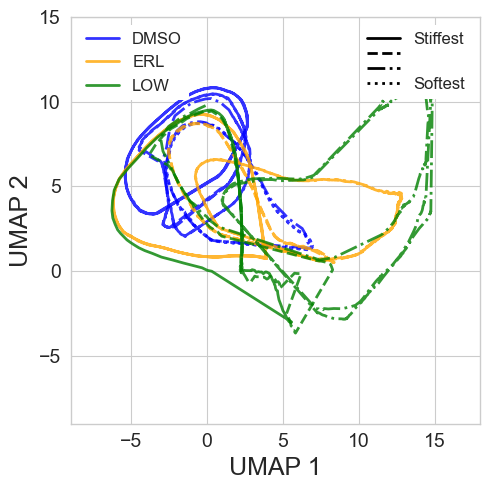

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

# canonical stiffness metric axis from plot_lyapunov_fits.py
x = np.linspace(0.0, 3.0, 151)

def nearest_index_to_target(vals, x, target, window=0.15):
    """
    Find the index of the minimum Lyapunov value near a target x location.
    Searches within [target - window, target + window].
    """
    mask = (x >= target - window) & (x <= target + window)
    idxs = np.where(mask)[0]
    if len(idxs) == 0:
        raise ValueError(f"No indices found near target {target}")
    local_vals = vals[idxs]
    return idxs[np.nanargmin(local_vals)]

def first_point_attractor_index(treatment):
    """
    Return the first steady-state index for a treatment from the summary table.
    Assumes summary_by_treatment contains dyn_state.
    """
    states = summary_by_treatment[treatment]["dyn_state"]
    idxs = np.where(states == "steady_state")[0]
    if len(idxs) == 0:
        raise ValueError(f"No point attractor found for {treatment}")
    return int(idxs[0])

# -----------------------------
# Choose the example indices
# -----------------------------
selected = {
    "LOW": [
        0,  # stiffness metric 0
        nearest_index_to_target(summary_by_treatment["LOW"]["mean_lyap"], x, 2.3, window=0.2),
        150,  # stiffness metric 3
        # first_point_attractor_index("LOW"),   # point attractor section
    ],
    "ERL": [
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2),
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 2.0, window=0.25),
        150,  # stiffness metric 3
    ],
    "DMSO": [
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.0, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.6, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 2.5, window=0.25),
        150,  # stiffness metric 3
    ],
}

# remove duplicates while preserving order
for treatment in selected:
    seen = set()
    selected[treatment] = [i for i in selected[treatment] if not (i in seen or seen.add(i))]

# print what was selected so you can verify
for treatment, idxs in selected.items():
    print(f"{treatment}:")
    for i in idxs:
        print(f"  index={i:3d}, stiffness={x[i]:.3f}, lyap={summary_by_treatment[treatment]['mean_lyap'][i]:.5f}")

# -----------------------------
# One combined figure
# -----------------------------
fig, ax = plt.subplots(figsize=(5, 5))

# darker = higher stiffness, lighter = lower stiffness
style_map = {
    "DMSO": {"cmap": plt.cm.Blues,  "linestyle": "-"},
    "ERL":  {"cmap": plt.cm.Oranges, "linestyle": "-"},
    "LOW":  {"cmap": plt.cm.Greens, "linestyle": "-"},
}

norm_stiff = Normalize(vmin=0.0, vmax=3.0)

file_map = {
    "DMSO": filenames_dmso,
    "ERL": filenames_erl,
    "LOW": low_embed,
}

for treatment, color in zip(["DMSO", "ERL", "LOW"], ['Blue', 'Orange', 'Green']):
    file_list = file_map[treatment]
    cmap = style_map[treatment]["cmap"]
    # linestyle = style_map[treatment]["linestyle"]
    # linestyles = [(0, (1, 10)), (0, (3, 10, 1, 10)), (0, (5, 10)), '-']
    # print(len(selected[treatment]))
    linestyles = [':', '-.', '--', '-']

    for i, ls in zip(selected[treatment], linestyles[-len(selected[treatment]):]):
        f = file_list[i]
        tmp_emb = np.genfromtxt(f, delimiter=",")
        tmp_l = int(len(tmp_emb) / 2)

        # color = cmap(norm_stiff(x[i]))
        print(i)
        # label = f"{treatment} | x={x[i]:.2f} | idx={i}"
        label = treatment if ls == '-' else None
        if treatment == "LOW" and i == first_point_attractor_index("LOW"):
            # for tmp in tmp_emb:
            #     print(tmp)
            # print(tmp_l)
            label = f"{treatment} point | x={x[i]:.2f} | idx={i}"
            marker_dict = {'marker': 'o',
                           'ms': 10,
                           'mec': 'black',}

        else:
            marker_dict = {}

        ax.plot(
            tmp_emb[:tmp_l, 0],
            tmp_emb[:tmp_l, 1],
            color=color,
            linestyle=ls,
            linewidth=2,
            alpha=0.8,
            label=label,
            **marker_dict,
        )

ax.set_xlabel("UMAP 1", fontsize=18)
ax.set_ylabel("UMAP 2", fontsize=18)
ax.tick_params(axis="both", labelsize=14)


ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])

# cleaner legend
leg1 = ax.legend(fontsize=12, loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=1)

# handles, labels = plt.gca().get_legend_handles_labels()

# Create new legend entries
line_solid = Line2D([0], [0], color='black', lw=2, ls='-')  # line
line_dashed = Line2D([0], [0], color='black', lw=2, ls='--')
line_dashdot = Line2D([0], [0], color='black', lw=2, ls='-.')
line_dotted = Line2D([0], [0], color='black', lw=2, ls=':')

# Append them
handles = [line_solid, line_dashed, line_dashdot, line_dotted]
labels = ['Stiffest', '', '', 'Softest']
leg2 = ax.legend(handles, labels, fontsize=12, loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=1, ncol=1, labelspacing=0)

# texts = leg2.get_texts()
#
# # Only apply monospace to arrow pieces
# texts[1].set_fontfamily('monospace')
# texts[2].set_fontfamily('monospace')

ax.add_artist(leg1)


# boxed axes
for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(True)
    ax.spines[side].set_linewidth(1.0)



plt.tight_layout()
plt.show()

In [45]:
xmin, xmax = -9, 18
ymin, ymax = -5, 19
plt.style.use('default')

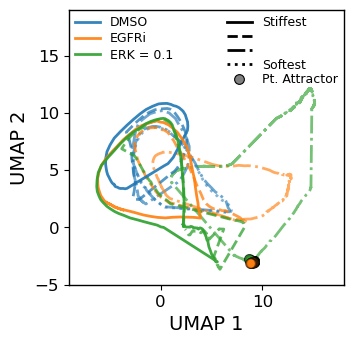

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import Divider, Size

x = np.linspace(0.0, 3.0, 151)

def nearest_index_to_target(vals, x, target, window=0.15):
    mask = (x >= target - window) & (x <= target + window)
    idxs = np.where(mask)[0]
    if len(idxs) == 0:
        raise ValueError(f"No indices found near target {target}")
    return idxs[np.nanargmin(vals[idxs])]

def first_point_attractor_index(treatment):
    states = summary_by_treatment[treatment]["dyn_state"]
    idxs = np.where(states == "steady_state")[0]
    if len(idxs) == 0:
        raise ValueError(f"No point attractor found for {treatment}")
    return int(idxs[0])

selected = {
    "DMSO": [
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.0, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.6, window=0.2),
        117,
        150,
    ],
    "ERL": [
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2),
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 2.0, window=0.25),
        150,
    ],
    "LOW": [
        0,
        nearest_index_to_target(summary_by_treatment["LOW"]["mean_lyap"], x, 2.3, window=0.2),
        150,
    ],
}

for treatment in selected:
    seen = set()
    selected[treatment] = [i for i in selected[treatment] if not (i in seen or seen.add(i))]

# ── Figure setup ──────────────────────────────────────────────────────────────
# ===== SHARED axes-box geometry — keep IDENTICAL in every figure to be matched =====
BOX_W, BOX_H = 2.75, 2.75     # the plotting box, in inches (this is the thing being matched)
LEFT, RIGHT  = 0.90, 0.15   # left margin holds the y-label + decimal y-ticks
BOTTOM, TOP  = 0.55, 0.15
figW = LEFT + BOX_W + RIGHT
figH = BOTTOM + BOX_H + TOP

fig = plt.figure(figsize=(figW, figH))
fig.set_layout_engine('none')          # required — Divider places the axes manually
h = [Size.Fixed(LEFT), Size.Fixed(BOX_W), Size.Fixed(RIGHT)]
v = [Size.Fixed(BOTTOM), Size.Fixed(BOX_H), Size.Fixed(TOP)]
div = Divider(fig, (0, 0, 1, 1), h, v, aspect=False)
ax = fig.add_axes(div.get_position(), axes_locator=div.new_locator(nx=1, ny=1))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

linestyles = [":",  "-.", "--", "-"]
linewidths = [2.0,  2.0,  2.0, 2.0]
alphas     = [0.55, 0.65, 0.75, 0.90]
zorders    = [1,    2,    3,    4]

file_map  = {"DMSO": filenames_dmso, "ERL": filenames_erl, "LOW": low_embed}
color_map = {"DMSO": "#1f77b4", "ERL": "#ff7f0e", "LOW": "#2ca02c"}
label_dict = {"ERL": "EGFRi", "LOW": "ERK = 0.1"}

lengths_map = {
    "DMSO": [55, 100, 45, 45],   # one length per selected index, same order as selected[...]
    "ERL":  [195, 62, 60],
    "LOW":  [100, 100, 100],
}

# ── Trajectories ──────────────────────────────────────────────────────────────
for treatment in ["DMSO", "ERL", "LOW"]:
    file_list = file_map[treatment]
    color     = color_map[treatment]
    n_sel     = len(selected[treatment])

    for rank, i in enumerate(selected[treatment]):
        ls  = linestyles[-n_sel:][rank]
        lw  = linewidths[-n_sel:][rank]
        alp = alphas[-n_sel:][rank]
        zo  = zorders[-n_sel:][rank]

        tmp_emb = np.genfromtxt(file_list[i], delimiter=",")
        tmp_l   = lengths_map[treatment][rank]

        label = label_dict.get(treatment, treatment) if ls == "-" else "_nolegend_"

        if (treatment == "LOW") & (rank == 0):
            ax.plot(
            tmp_emb[3000:, 0],
            tmp_emb[3000:, 1],
            color=color,
            linestyle=ls,
            linewidth=lw,
            alpha=alp,
            zorder=zo,
            label=label,
        )
        else:
            ax.plot(
            tmp_emb[:tmp_l, 0],
            tmp_emb[:tmp_l, 1],
            color=color,
            linestyle=ls,
            linewidth=lw,
            alpha=alp,
            zorder=zo,
            label=label,
        )

# ── Point attractors ──────────────────────────────────────────────────────────
# Collect steady-state indices per treatment; skip treatments with none
attractor_map = {
    "LOW": (lyap_df, low_embed),
    "ERL": (lyap_df, filenames_erl),
    "DMSO": (lyap_df, filenames_dmso),
}

for treatment, (df, file_list) in attractor_map.items():
    ss_idx = df[
        (df.treatment == treatment) & (df.dyn_state == "steady_state")
    ]["index"].values

    if len(ss_idx) == 0:
        continue

    # Use the last point of each embedding file as the attractor coordinate
    coords = np.array([
        np.genfromtxt(file_list[i], delimiter=",")[-1] for i in ss_idx
    ])

    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=50,
        facecolor=color_map[treatment],
        edgecolor="black",
        linewidths=0.8,
        zorder=5,
        alpha=0.5,
    )

# ── Axis formatting ───────────────────────────────────────────────────────────
ax.set_xlabel("UMAP 1", fontsize=14)
ax.set_ylabel("UMAP 2", fontsize=14)
ax.tick_params(axis="both", labelsize=12)
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
ax.grid(False)

for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(True)
    ax.spines[side].set_color("black")
    ax.spines[side].set_linewidth(1.0)

# ── Legend 1: treatment colours ───────────────────────────────────────────────
leg1 = ax.legend(
    fontsize=9, loc="upper left", labelspacing=0.25, borderpad=0,
    frameon=False, facecolor="white", edgecolor="lightgrey", framealpha=1,
)

# ── Legend 2: stiffness linestyle key + point attractor marker ───────────────
stiff_handles = [
    Line2D([0], [0], color="black", lw=2.0, ls="-",  label="Stiffest"),
    Line2D([0], [0], color="black", lw=2.0, ls="--", label=""),
    Line2D([0], [0], color="black", lw=2.0, ls="-.", label=""),
    Line2D([0], [0], color="black", lw=2.0, ls=":",  label="Softest"),
    Line2D([0], [0], color="black", lw=0,   ls="",
           marker="o", markersize=7,
           markerfacecolor="grey", markeredgecolor="black",
           markeredgewidth=0.8,    label="Pt. Attractor"),
]

leg2 = ax.legend(
    handles=stiff_handles,
    fontsize=9, loc="upper right", labelspacing=0.1, borderpad=0,
    frameon=False, facecolor="white", framealpha=1, title_fontsize=11,
)

ax.add_artist(leg1)

fig4d = Path(SAVE_DIR, 'fig4d.svg')

if SAVEFILES and (OVERWRITE or not fig4d.exists()):
    plt.savefig(fig4d)
else:
    plt.figure()

plt.show()

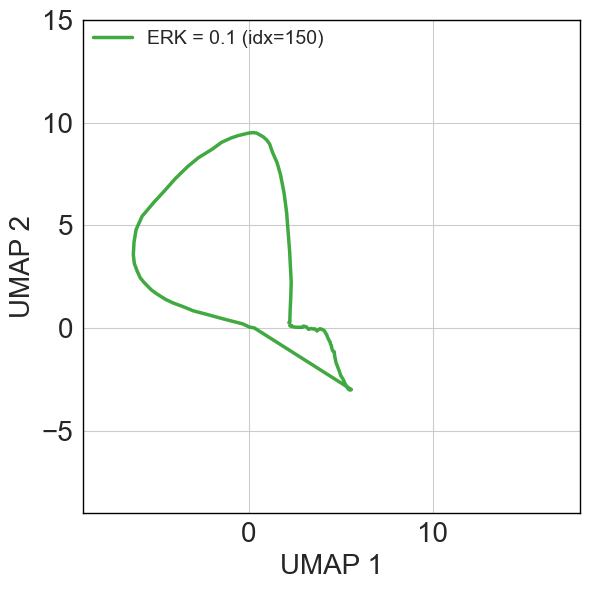

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── Pick which trajectory to plot ────────────────────────────────────────────
treatment = "LOW"   # "DMSO", "ERL", or "LOW"
idx       = 2        # position into selected[treatment]: 0 = softest, last = stiffest
tmp_l     = 100      # trajectory length

x = np.linspace(0.0, 3.0, 151)

# ── Shared maps ──────────────────────────────────────────────────────────────
file_map  = {"DMSO": filenames_dmso, "ERL": filenames_erl, "LOW": low_embed}
color_map = {"DMSO": "#1f77b4", "ERL": "#ff7f0e", "LOW": "#2ca02c"}
label_dict = {"DMSO": "DMSO", "ERL": "EGFRi", "LOW": "ERK = 0.1"}

selected = {
    "DMSO": [
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.0, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.6, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 2.5, window=0.25),
        150,
    ],
    "ERL": [
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2),
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 2.0, window=0.25),
        150,
    ],
    "LOW": [
        0,
        nearest_index_to_target(summary_by_treatment["LOW"]["mean_lyap"], x, 2.3, window=0.2),
        150,
    ],
}

# Style ladders (softest → stiffest)
linestyles = [":",  "-.", "--", "-"]
linewidths = [1.0,  1.5,  2.0, 2.5]
alphas     = [0.55, 0.65, 0.75, 0.90]
zorders    = [1,    2,    3,    4]

# Resolve which file + style this single trajectory gets
sel    = selected[treatment]
n_sel  = len(sel)
i      = sel[idx]
# i = 117
ls     = linestyles[-n_sel:][idx]
lw     = linewidths[-n_sel:][idx]
alp    = alphas[-n_sel:][idx]
zo     = zorders[-n_sel:][idx]
color  = color_map[treatment]
files  = file_map[treatment]

# ── Figure ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

tmp_emb = np.genfromtxt(files[i], delimiter=",")
tmp_l   = min(tmp_l, len(tmp_emb))

ax.plot(
    tmp_emb[:tmp_l, 0],
    tmp_emb[:tmp_l, 1],
    color=color, linestyle=ls, linewidth=lw,
    alpha=alp, zorder=zo,
    label=f"{label_dict[treatment]} (idx={i})",
)

# ax.plot(
#     tmp_emb[:, 0],
#     tmp_emb[:, 1],
#     color=color, linestyle=ls, linewidth=lw,
#     alpha=alp, zorder=zo,
#     label=f"{label_dict[treatment]} (idx={i})",
# )

# Point attractor for this specific embedding, if it's a steady state
is_ss = (
    (lyap_df.treatment == treatment)
    & (lyap_df.dyn_state == "steady_state")
    & (lyap_df["index"] == i)
).any()

if is_ss:
    end_pt = np.genfromtxt(files[i], delimiter=",")[-1]
    ax.scatter(
        end_pt[0], end_pt[1],
        s=50, facecolor=color, edgecolor="black",
        linewidths=0.8, zorder=5, alpha=0.5,
    )

# ── Axis formatting ──────────────────────────────────────────────────────────
ax.set_xlabel("UMAP 1", fontsize=20)
ax.set_ylabel("UMAP 2", fontsize=20)
ax.tick_params(axis="both", labelsize=20)
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])

for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(True)
    ax.spines[side].set_color("black")
    ax.spines[side].set_linewidth(1.0)

ax.legend(
    fontsize=14, loc="upper left", labelspacing=0.25, borderpad=0,
    frameon=False, facecolor="white", edgecolor="lightgrey", framealpha=1,
)

plt.tight_layout()
plt.show()

In [54]:
x = np.linspace(0.0, 3.0, 151)

def get_minima_indices(vals, prominence=0.002):
    minima, _ = find_peaks(-vals, prominence=prominence)
    return minima

def pick_min_in_range(vals, x, idxs, xmin, xmax):
    candidates = [i for i in idxs if xmin <= x[i] <= xmax]
    if not candidates:
        return None
    return min(candidates, key=lambda i: vals[i])

In [51]:
targets = {
    "DMSO": [(0.9, 1.1), (1.5, 1.7), (2.4, 2.6), (2.9, 3.1)],
    "ERL":  [(0.6, 0.9), (1.8, 2.2), (2.9, 3.1)],
    "LOW":  [(2.2, 2.4), (2.9, 3.1)],
}

In [55]:
selected = {}

# --- DMSO ---
vals = summary_by_treatment["DMSO"]["mean_lyap"]
mins = get_minima_indices(vals)

selected["DMSO"] = [
    pick_min_in_range(vals, x, mins, 0.9, 1.1),
    pick_min_in_range(vals, x, mins, 1.5, 1.7),
    pick_min_in_range(vals, x, mins, 2.4, 2.6),
    150  # stiffness = 3
]

# --- ERL ---
vals = summary_by_treatment["ERL"]["mean_lyap"]
mins = get_minima_indices(vals)

selected["ERL"] = [
    pick_min_in_range(vals, x, mins, 0.6, 0.9),
    pick_min_in_range(vals, x, mins, 1.8, 2.2),
    150
]

# --- LOW ---
vals = summary_by_treatment["LOW"]["mean_lyap"]
mins = get_minima_indices(vals)

selected["LOW"] = [
    0,  # stiffness = 0
    pick_min_in_range(vals, x, mins, 2.2, 2.4),
    150
]

# add LOW point attractor
low_point_idx = lyap_df[
    (lyap_df["treatment"] == "LOW") &
    (lyap_df["dyn_state"] == "steady_state")
]["index"].values[0]

selected["LOW"].append(int(low_point_idx))

# clean None values
for k in selected:
    selected[k] = [i for i in selected[k] if i is not None]

### Downsample ODE trajectories to 1/10 (100 trajectories)

In [21]:
filenames_dmso_100 = filenames_dmso[0::10]
filenames_erl_100 = filenames_erl[0::10]

In [22]:
len(filenames_erl_100)

100

C:\Users\olesk\AppData\Local\Temp\ipykernel_28780\815787847.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')


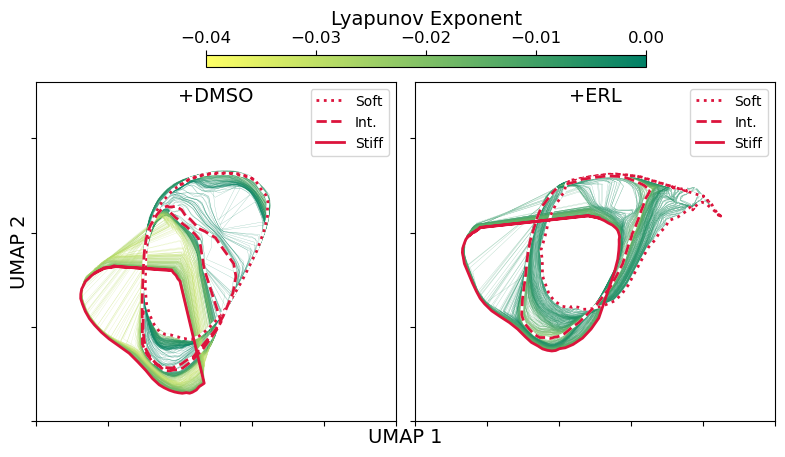

In [36]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_dmso[ii])), lw=0.2, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_erl[ii])), lw=0.2, alpha=0.5)
    ii+=1
    

    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 60
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    


tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 75
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)     


axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0], 
             orientation='horizontal', location='top', label='Lyapunov Exponent')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVE_DIR, 'fig4a_lyap.png')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [16]:
ode_divs_erl[0]

71.94

In [17]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 24,
         'axes.titlesize': 24,
         'axes.edgecolor': "black",
         'xtick.labelsize': 20,
         'ytick.labelsize': 20}
plt.rcParams.update(params)

(-0.05, 0.02)

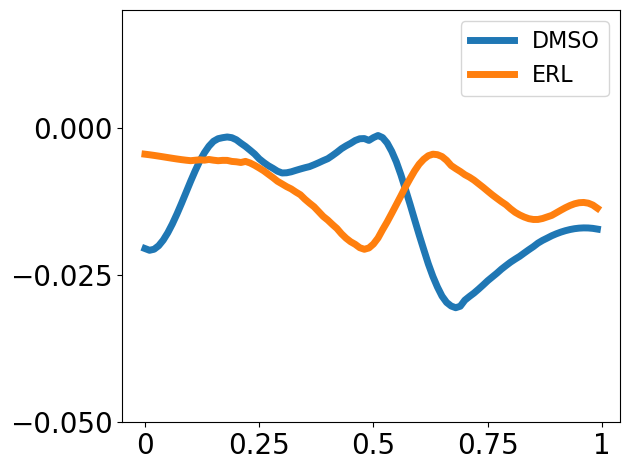

In [18]:
plt.plot(lyap_dmso, label="DMSO", lw=5)
plt.plot(lyap_erl, label='ERL', lw=5)
plt.legend(fontsize=16)
locs, labels = plt.xticks() 
plt.xticks([0, 25, 50, 75, 100], [0, 0.25, 0.5, 0.75, 1])
plt.yticks([-0.05, -0.025, 0])

plt.ylim(-0.05, 0.02)

### Load and plot ODE trajectories

In [16]:
output_from = 1 # 1: original, 2: PSO params, 3: 03_ECM_model_output.ipynb, 4: 04_Stoch_sims_for_UMAP.ipynb

if output_from == 1:
    embed_source = 'orig'
elif output_from == 2:
    embed_source = 'psoparams'
else:
    embed_source = f'from_0{output_from}'

if SET_JPARAM:
    all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{embed_source}_{sys_name}.sav'))
else:
    all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_{embed_source}.sav'))
all_embed_odes.shape

(20000, 2)

#### Define conditions and annotations

In [17]:
conds = ['0.0 DMSO', '0.3 DMSO', '0.5 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 ERL', '0.3 ERL', '0.5 ERL', '0.75 ERL', '1.0 ERL',]
colors_blue = plt.cm.Blues(np.linspace(0,1,7))
colors_red = plt.cm.Reds(np.linspace(0,1,6))
cond_colors = [colors_blue[2], colors_blue[3], colors_blue[4], colors_blue[5], colors_blue[6], colors_red[1], colors_red[2], colors_red[3], colors_red[4], colors_red[5],]
conds_idx = [0,1,2,3,4,5,6,7,8,9,]
plot_ode_len = [120,100,0,100,60,150,0,80,0,60,]
line_type = ['-', '-', '-', '-', '-', '--', '--', '--', '--', '--',]


In [21]:
# plot parameters
trk_len = 2000 # length of ODE trajectories
size = (3,3)
l = trk_len
lw=2
fontsize = 7
embed_array = all_embed_odes

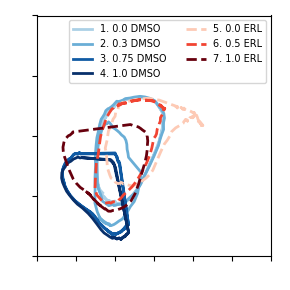

In [22]:
fig = plt.figure(figsize=size)

for i,x in enumerate([0,1,3,4,5,7,9,]):
    plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
             embed_array[x*l:x*l+plot_ode_len[x],1], 
             ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,1,2,3,4,5,6,]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], 
           loc="upper right", ncol=2, fontsize=fontsize)